# Cobre · Transaction Corridor Analysis — analysis walkthrough
**L2 Business Architect Assessment** · 50,000 transactions · 5,000 users · Jul–Dec 2025

This notebook walks through the analysis in the order I did it: validate the data, answer Part 1, investigate the
USD→MXN failures (Part 2) and choose the corridor to prioritize (Part 3).

**Single source of truth.** The notebook does not compute anything on its own. It calls the `cobre` package in
`python/`, the same code that produces the Excel workbook and the PDF deliverable, so every number here matches
them exactly. Markdown cells explain the reasoning; figures are printed by the code.

> To run it, place `transactions.csv` and `users.csv` in the repository root (they are not versioned).

In [1]:
import sys, tempfile
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "python"))

import pandas as pd
from IPython.display import Image, Markdown, display

from cobre import answers as A, part1, part2, part3, quality
from cobre.data import get_data, load_raw
from cobre.fmt import cell, kind, label
from build_document import make_charts

tx_raw, _ = load_raw()
df, users = get_data()
results = [quality.run(tx_raw, users, df), *part1.run(df, users), part2.run(df), part3.run(df)]
R = {r.name: r for r in results}                       # results by module
T = {k: v for r in results for k, v in r.tables.items()}  # every result table
QA = {q.code: q for q in A.qa(R)}                      # every question with its answer
charts = make_charts(R, Path(tempfile.mkdtemp()))
print(f"{len(df):,} transactions · {len(users):,} users · {len(T)} result tables · {len(QA)} questions answered")

50,000 transactions · 5,000 users · 45 result tables · 16 questions answered


In [2]:
def pretty(table):
    """Display a result table with the same labels and formats used in Excel and the PDF."""
    d = table if isinstance(table.index, pd.RangeIndex) else table.reset_index()
    out = pd.DataFrame({label(str(c)): [cell(v, kind(str(c), v)) for v in d[c]] for c in d.columns})
    return out.style.hide(axis="index")


def answer(code, tables=True):
    """Show one assessment question, its answer and (optionally) its supporting tables."""
    q = QA[code]
    display(Markdown(f"**{q.code} · {q.question}**\n\n> {q.answer}"))
    if tables:
        for t in q.tables:
            display(pretty(T[t]))

## 0 · Data quality first
Before answering anything I checked that the data could be trusted: completeness, duplicates, referential
integrity (every transaction has a known user), consistent corridors and the real date range.

In [3]:
display(pretty(T["q_checks"]))
for note in A.quality_notes(R)[:3]:
    display(Markdown("- " + note))

Check,Value
Transaction rows,"50,000"
User rows,"5,000"
Empty cells (transactions),0
Empty cells (users),0
Duplicate transaction_id,0
Duplicate user_id,0
Transactions with unknown user,0
Amounts <= 0,0
First date,2025-07-01
Last date,2025-12-30


- Clean data: no empty cells, no duplicates, no orphan users, and corridors consistent with origin/destination.

- The segment in transactions.csv differs from users.csv in 61% of rows and 4,970 users appear with more than one segment. The transaction segment is used (it is the one the brief describes) and the mismatch is flagged as a data-governance task.

- Data ends on 2025-12-30: monthly metrics are computed per day with data.

**Takeaway:** the data is clean. The one inconsistency is that a user's segment in `transactions.csv` often differs
from their profile in `users.csv`; I use the transaction segment (the one the brief describes) and flag the rest as a
data-governance task.

## Part 1 · Data analysis
**Approach.** A single function (`metrics.summarize`) computes the same KPIs for any grouping (volume, value,
success rate, ticket, users, transactions per day). Monthly and weekday comparisons use *transactions per day with
data*, so months or weekdays with fewer days are not penalized.

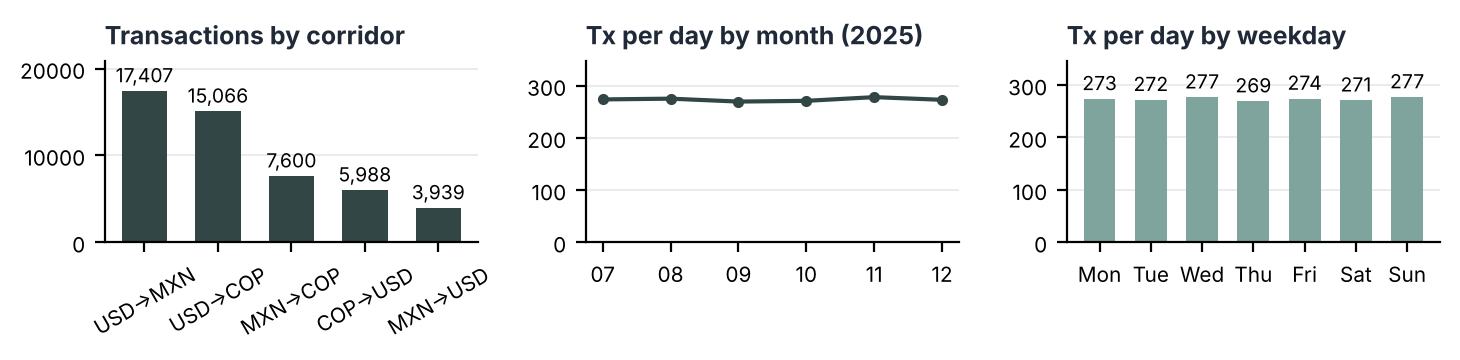

In [4]:
display(Image(charts["part1"]))

### 1.1 Corridor performance

In [5]:
for c in ["1.1a", "1.1b", "1.1c", "1.1d"]:
    answer(c)

**1.1a · What are the top 5 payment corridors by transaction volume?**

> 1. USD→MXN (34.8%) · 2. USD→COP (30.1%) · 3. MXN→COP (15.2%) · 4. COP→USD (12.0%) · 5. MXN→USD (7.9%). There are only 5 corridors, so the top 5 is the full set; the first two account for 65% of transactions.

Corridor,Transactions,% of tx
USD_MXN,"17,407",34.8%
USD_COP,"15,066",30.1%
MXN_COP,"7,600",15.2%
COP_USD,"5,988",12.0%
MXN_USD,"3,939",7.9%


**1.1b · What are the top 5 corridors by transaction value (total USD)?**

> 1. USD→MXN (US$126.6M) · 2. USD→COP (US$77.8M) · 3. MXN→COP (US$27.5M) · 4. COP→USD (US$26.9M) · 5. MXN→USD (US$22.6M). USD→MXN concentrates **45.0% of value** with 34.8% of transactions.

Corridor,Value (USD),Successful value,% of value
USD_MXN,"US$126,567,091","US$101,461,890",45.0%
USD_COP,"US$77,818,846","US$73,857,675",27.6%
MXN_COP,"US$27,520,178","US$26,113,235",9.8%
COP_USD,"US$26,914,517","US$25,792,929",9.6%
MXN_USD,"US$22,647,843","US$21,494,349",8.0%


**1.1c · Which corridors have the highest success rates?**

> COP→USD leads with 95.7%. All corridors are around 95% except **USD→MXN, which drops to 81.7%**: it is the only reliability problem.

Corridor,Success rate,Failure rate
COP_USD,95.7%,4.3%
MXN_USD,95.3%,4.7%
USD_COP,94.9%,5.1%
MXN_COP,94.8%,5.2%
USD_MXN,81.7%,18.3%


**1.1d · What is the average transaction size by corridor?**

> USD→MXN US$7,271 · MXN→USD US$5,750 · USD→COP US$5,165 · COP→USD US$4,495 · MXN→COP US$3,621. The mean is ~1.8× the median in every corridor: a few large enterprise payments pull the average up.

Corridor,Avg ticket,Median ticket
USD_MXN,"US$7,271","US$4,055"
MXN_USD,"US$5,750","US$3,244"
USD_COP,"US$5,165","US$2,890"
COP_USD,"US$4,495","US$2,507"
MXN_COP,"US$3,621","US$2,061"


### 1.2 User behavior

In [6]:
for c in ["1.2a", "1.2b", "1.2c"]:
    answer(c)

**1.2a · What's the average number of transactions per user?**

> **10.0 transactions per user** (median 10, max 21). All 5,000 registered users transacted at least once.

Metric,Value
Registered users,"5,000"
Users with at least 1 tx,"5,000"
Avg tx per active user,10
Avg tx per registered user,10
Median,10
P90,14
Min,1
Max,21


Tx per user,Users
1,3
2,8
3,35
4,96
5,183
6,291
7,432
8,583
9,658
10,634


**1.2b · Who are the top 10 users by transaction volume?**

> The leader is USR_4714 with 21 transactions; the top 10 make between 20 and 21, only 2× the average. No user concentrates volume.

User,Country,Segment (profile),Transactions,Value (USD),Avg ticket,Success rate
USR_4714,Mexico,retail,21,"US$149,781","US$7,132",95.2%
USR_4823,Mexico,retail,21,"US$142,464","US$6,784",100.0%
USR_1798,Mexico,enterprise,21,"US$132,087","US$6,290",100.0%
USR_1843,Mexico,sme,21,"US$88,423","US$4,211",66.7%
USR_2234,Mexico,sme,20,"US$159,192","US$7,960",90.0%
USR_3778,Colombia,sme,20,"US$129,216","US$6,461",95.0%
USR_0336,Colombia,enterprise,20,"US$126,058","US$6,303",90.0%
USR_4243,Mexico,enterprise,20,"US$97,371","US$4,869",95.0%
USR_1186,Colombia,retail,20,"US$94,008","US$4,700",100.0%
USR_3013,Mexico,retail,20,"US$91,770","US$4,588",95.0%


**1.2c · How does user behavior differ between Mexico and Colombia?**

> Mexico accounts for 59.1% of transactions because it has more users, but **per user they behave the same**: 10.0 vs 10.0 tx/user, ticket US$5,595 vs US$5,679, success 90.4% vs 90.5%, same corridor and segment mix. The real difference is the destination: money **arriving** in Mexico fails 18.3% vs 5.1% for money arriving in Colombia.

Country,Transactions,Value (USD),Successful value,Failed value,Success rate,Avg ticket,Median ticket,Users,Days with data,Failure rate,Failed value %,Tx per day,Tx per user,% of tx,% of value
Colombia,"20,474","US$116,263,408","US$102,784,288","US$13,479,120",90.5%,"US$5,679","US$3,315","2,043",183,9.5%,11.6%,111.9,10.02,40.9%,41.3%
Mexico,"29,526","US$165,205,068","US$145,935,790","US$19,269,278",90.4%,"US$5,595","US$3,314","2,957",183,9.6%,11.7%,161.3,9.99,59.1%,58.7%


Destination,Transactions,Value (USD),Successful value,Failed value,Success rate,Avg ticket,Median ticket,Users,Days with data,Failure rate,Failed value %,Tx per day,Tx per user,% of tx,% of value
CO,"22,666","US$105,339,024","US$99,970,910","US$5,368,114",94.9%,"US$4,647","US$2,714","4,957",183,5.1%,5.1%,123.9,4.57,56.6%,45.4%
MX,"17,407","US$126,567,091","US$101,461,890","US$25,105,201",81.7%,"US$7,271","US$4,055","4,855",183,18.3%,19.8%,95.1,3.59,43.4%,54.6%


### 1.3 Time patterns

In [7]:
for c in ["1.3a", "1.3b", "1.3c"]:
    answer(c)

**1.3a · What days of the week have the highest transaction volume?**

> Sunday has the highest daily average and Thursday the lowest, but the gap between them is only 2.8%: **there is no dominant day**; volume is even across the week.

Day,Transactions,Value (USD),Days with data,Tx per day,Success rate
Monday,"7,110","US$40,542,300",26,273.5,90.2%
Tuesday,"7,337","US$41,188,127",27,271.7,90.3%
Wednesday,"7,190","US$39,764,578",26,276.5,90.7%
Thursday,"6,998","US$39,170,174",26,269.2,90.4%
Friday,"7,126","US$40,172,989",26,274.1,90.4%
Saturday,"7,040","US$39,775,683",26,270.8,90.3%
Sunday,"7,199","US$40,854,625",26,276.9,90.7%


**1.3b · Are there any notable hourly patterns?**

> All activity happens between 8:00 and 19:59 (banking hours), with no overnight transactions. The peak is at 10:00, but the variation across hours is 4.8%: within the window volume is flat.

Hour,Transactions,Value (USD),% of tx,Success rate
8,"4,205","US$23,770,738",8.4%,90.6%
9,"4,106","US$23,435,016",8.2%,90.5%
10,"4,304","US$24,090,542",8.6%,90.2%
11,"4,128","US$22,698,878",8.3%,90.9%
12,"4,167","US$23,575,185",8.3%,90.9%
13,"4,227","US$24,150,645",8.5%,90.2%
14,"4,209","US$23,471,982",8.4%,90.3%
15,"4,139","US$23,203,119",8.3%,90.6%
16,"4,102","US$23,116,634",8.2%,89.8%
17,"4,116","US$23,537,836",8.2%,90.5%


Hour,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
8,616,601,561,601,593,583,650
9,593,609,581,576,615,593,539
10,604,606,628,648,619,610,589
11,541,614,665,548,560,611,589
12,571,657,587,587,614,563,588
13,587,592,587,579,604,616,662
14,598,618,635,560,597,565,636
15,622,613,569,579,575,597,584
16,586,599,620,575,612,566,544
17,555,630,573,582,574,584,618


**1.3c · Has transaction volume been growing or declining over the 6-month period?**

> **It is flat.** 274 tx/day in July vs 273 in December (-0.3%); the linear trend is 0.08% per month. Only USD→MXN is growing in value (+4.2% Q4 vs Q3).

Month,Transactions,Value (USD),Days with data,Tx per day,USD per day,MoM change,Success rate
2025-07,"8,479","US$47,584,065",31,273.5,"US$1,534,970",,90.6%
2025-08,"8,524","US$47,728,045",31,275.0,"US$1,539,614",0.5%,90.7%
2025-09,"8,082","US$45,149,081",30,269.4,"US$1,504,969",-2.0%,90.0%
2025-10,"8,395","US$48,041,034",31,270.8,"US$1,549,711",0.5%,90.4%
2025-11,"8,336","US$46,860,315",30,277.9,"US$1,562,011",2.6%,90.5%
2025-12,"8,184","US$46,105,935",30,272.8,"US$1,536,864",-1.8%,90.3%


## Part 2 · Why does USD→MXN fail?
**Approach.** The brief states three patterns (segment, transaction size, Friday). Instead of taking them as given,
I tested each one and always compared USD→MXN **against the other corridors**: a pattern only explains the problem
if it is specific to this corridor.

In [8]:
display(pretty(T["p2_overview"]))

Metric,Failure rate,Failed value %,Transactions,failed_tx
USD_MXN,18.3%,19.8%,"17,407","3,177"
Other corridors,4.9%,4.9%,"32,593","1,604"
Total,9.6%,11.6%,"50,000","4,781"


### Step 1 · Segment
Does one segment explain the failures, or does every segment fail more in this corridor?

In [9]:
display(pretty(T["p2_by_segment"]))

Segment,Corridor failure,Corridor tx,Corridor failures,Other corridors,Times vs others,% of failures
enterprise,23.9%,"2,653",634,5.0%,4.8×,20.0%
retail,19.5%,"8,550","1,667",5.0%,3.9×,52.5%
sme,14.1%,"6,204",876,4.8%,3.0×,27.6%


Every segment fails several times more than in the other corridors, so the problem is not one customer type.

### Step 2 · Transaction size

In [10]:
display(pretty(T["p2_by_amount_band"].dropna(subset=["corridor_failure_rate"])))

Amount (USD),Corridor failure,Corridor tx,Corridor failures,Other corridors,Times vs others,% of failures
1k-2.5k,19.7%,"3,960",782,5.1%,3.9×,24.6%
2.5k-5k,18.0%,"5,948","1,069",5.0%,3.6×,33.6%
5k-10k,13.7%,"4,409",604,4.6%,3.0×,19.0%
>10k,23.4%,"3,090",722,5.0%,4.6×,22.7%


### Step 3 · Separate segment from size
Segments live in different amount ranges (retail is small, enterprise is large), so the two effects are mixed.
The matrix below shows it; then I isolate the amount effect *within one segment*: SME is the only segment whose
payments sit on both sides of US$10K.

In [11]:
display(pretty(T["p2_segment_x_band_count"]))
display(pretty(T["p2_threshold_sme"][["corridor_num_tx", "corridor_failed_tx", "corridor_failure_rate"]]))

Segment,1k-2.5k,2.5k-5k,5k-10k,>10k
enterprise,,,,"2,653"
retail,"3,960","4,590",,
sme,,"1,358","4,409",437


SME amount (USD),Corridor tx,Corridor failures,Corridor failure
<=8k,"4,059",542,13.4%
8k-9k,848,112,13.2%
9k-9.5k,427,65,15.2%
9.5k-10k,433,69,15.9%
10k-10.5k,437,88,20.1%


Within the same segment, the failure rate steps up right above US$10K: the threshold itself matters, which points to
a limit or compliance rule rather than to the customer.

### Step 4 · Day of the week
The brief suggests Fridays fail more. A chi-square test checks whether failure depends on the day or the segment.

In [12]:
display(pretty(T["p2_by_weekday"][["corridor_num_tx", "corridor_failure_rate", "rest_failure_rate"]]))
display(pretty(T["p2_significance"]))

Day,Corridor tx,Corridor failure,Other corridors
Monday,"2,584",18.8%,4.7%
Tuesday,"2,571",18.9%,4.7%
Wednesday,"2,484",17.0%,5.2%
Thursday,"2,383",18.8%,4.8%
Friday,"2,445",18.4%,5.0%
Saturday,"2,429",18.3%,5.1%
Sunday,"2,511",17.6%,4.8%


Metric,Chi²,p-value,Conclusion
user_segment,136.55,0.000,Significant difference (p<0.05)
weekday,5.08,0.534,Not significant: random noise


The segment effect is highly significant; the day effect is not (it is random noise), so the Friday pattern from
the brief does not hold in the data.

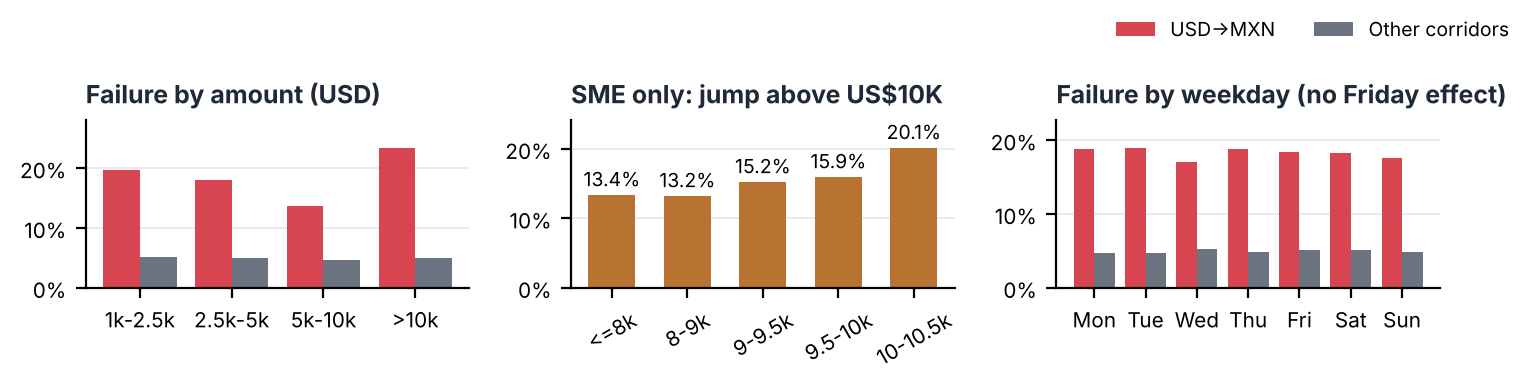

In [13]:
display(Image(charts["part2"]))

### Answers to Part 2

In [14]:
answer("2.1a", tables=False)
for c in ["2.1b", "2.1c", "2.2a", "2.2b"]:
    answer(c)

**2.1a · What patterns do you see in the failed transactions?**

> USD→MXN fails 18.3% of transactions (19.8% of value), 3.7× the other corridors (4.9%), and drives 66% of all Cobre failures. The data shows a higher rate than the 15% stated in the brief. (1) Every segment fails more than in other corridors, with a gradient: enterprise 23.9%, retail 19.5% and SME 14.1%; retail drives 52% of failures by volume. (2) Amount matters: payments >US$10K fail 23.4% and, within SME, the rate jumps from 13.7% to 20.1% when crossing US$10K. (3) The day does **not** matter: Fridays fail 18.4% and the weekly range is 17.0%–18.9% (chi², p=0.53); neither do hour or month. Failures are spread across 2,341 users: this is not a single customer.

**2.1b · What are 3 possible root causes for the high failure rate?**

> H1: a compliance/AML rule or payout-bank limit on payments >US$10K. H2: invalid beneficiary data (CLABE, name) in retail. H3: a structural issue with the MXN provider or settlement route that raises the baseline failure rate across the whole corridor.

Hypothesis,Evidence in the data,How to validate
H1 · Compliance (AML) rule or payout-bank limit on payments > US$10K,">10K fails 23.4%; within SME the rate jumps from 13.7% (≤10K) to 20.1% (>10K). In other corridors >10K fails 5.0%, the same as any amount.",Cross-check rejection/error codes from the MXN provider; review SPEI and payout-bank limits and screening rules; A/B test splitting or pre-approval.
"H2 · Invalid beneficiary/KYC data in retail (CLABE, name)","Retail fails 19.5% and accounts for 52.5% of failures, with tickets < US$4.2K.",Distribution of rejection reasons by segment; retry success rate after fixing data; validate CLABE at checkout and measure before/after.
H3 · Structural issue with the USD→MXN provider or settlement route,"Every segment, hour, day and month fails ~3-4× more than in other corridors: the issue belongs to the corridor, not to the customer or the calendar.",Compare failure rate by provider/payout bank and by outage timestamp; SLA and timeout logs; route a share of volume through an alternative provider.


**2.1c · How would you validate which root cause is correct?**

> Analyze rejection codes by segment and amount; compare failure rates by provider/payout bank; pilot CLABE validation at checkout and pre-approval of payments >US$10K with an A/B test. Details per hypothesis are in the “How to validate” column of the table above.

**2.2a · Estimate the monthly revenue loss from these failures (Cobre earns 0.5% per transaction).**

> At a 0.5% fee, the sample loses US$21K/month; scaled to Cobre's US$1.5B/month that is **US$669K/month**.

Scenario,Monthly value,Monthly failed value,Failed value %,Revenue lost / month,Gain at 5% / month,Gain at 5% (count-based),Annual gain
Sample (data as is),"US$21,094,515","US$4,184,200",19.8%,"US$20,921","US$15,647","US$13,976","US$187,768"
Scaled to US$1.5B/month,"US$674,500,531","US$133,790,475",19.8%,"US$668,952","US$500,327","US$446,900","US$6,003,927"
"Brief scenario (35%, 15%)","US$525,000,000","US$78,750,000",15.0%,"US$393,750","US$262,500","US$262,500","US$3,150,000"


**2.2b · If you could reduce the failure rate to 5%, what would be the monthly revenue gain?**

> Cutting failures to 5% recovers **US$500K/month (US$6.0M/year)**; under the brief's assumptions (35%, 15%) it would be US$262K/month. Attack H1 and H3 first, since they concentrate the lost value: agree limits and pre-approval for large payments with the payout bank, and test a second MXN provider. In parallel, add CLABE validation for retail (H2) and track the failure rate weekly by segment and amount band.

### Write-up as delivered (250-300 words)
The answers above, read in order, form the write-up in the PDF deliverable.

In [15]:
wu = A.p2_writeup(R)
display(Markdown("\n\n".join(f"**{h}.** {t}" for h, t in wu) + f"\n\n*{A.words(wu)} words*"))

**Diagnosis.** USD→MXN fails 18.3% of transactions (19.8% of value), 3.7× the other corridors (4.9%), and drives 66% of all Cobre failures. The data shows a higher rate than the 15% stated in the brief.

**Patterns.** (1) Every segment fails more than in other corridors, with a gradient: enterprise 23.9%, retail 19.5% and SME 14.1%; retail drives 52% of failures by volume. (2) Amount matters: payments >US$10K fail 23.4% and, within SME, the rate jumps from 13.7% to 20.1% when crossing US$10K. (3) The day does **not** matter: Fridays fail 18.4% and the weekly range is 17.0%–18.9% (chi², p=0.53); neither do hour or month. Failures are spread across 2,341 users: this is not a single customer.

**Three possible root causes.** H1: a compliance/AML rule or payout-bank limit on payments >US$10K. H2: invalid beneficiary data (CLABE, name) in retail. H3: a structural issue with the MXN provider or settlement route that raises the baseline failure rate across the whole corridor.

**Validation.** Analyze rejection codes by segment and amount; compare failure rates by provider/payout bank; pilot CLABE validation at checkout and pre-approval of payments >US$10K with an A/B test.

**Impact.** At a 0.5% fee, the sample loses US$21K/month; scaled to Cobre's US$1.5B/month that is **US$669K/month**. Cutting failures to 5% recovers **US$500K/month (US$6.0M/year)**; under the brief's assumptions (35%, 15%) it would be US$262K/month.

**Recommendation.** Attack H1 and H3 first, since they concentrate the lost value: agree limits and pre-approval for large payments with the payout bank, and test a second MXN provider. In parallel, add CLABE validation for retail (H2) and track the failure rate weekly by segment and amount band.

*267 words*

## Part 3 · Which corridor to prioritize in 2026?
**Approach.** A weighted decision matrix with the five criteria from the brief. Quantitative criteria come from the
data (scaled revenue, Q4 vs Q3 growth, success rate, recoverable revenue); market size and operational simplicity
are documented 1-5 judgments. Every criterion is min-max normalized, and a sensitivity check removes one criterion
at a time to see whether the winner changes.

In [16]:
display(pretty(T["p3_weights"]))
answer("3")

Metric,Weight
revenue_month_scaled,30.0%
growth_q4_vs_q3,15.0%
success_rate,15.0%
recoverable_revenue,20.0%
market_score,10.0%
simplicity_score,10.0%


**3 · Which ONE corridor should Cobre prioritize for growth investment in 2026?**

> **USD→MXN.** It is the largest, the only one growing and the one with the most revenue to recover (~US$500K/month). It wins the decision matrix with 0.85 vs 0.53 for USD→COP.

Corridor,Transactions,% of value,Monthly revenue (scaled),Growth Q4 vs Q3,Success rate,Recoverable / month,Market (1-5),Simplicity (1-5),Score,Rank
USD_MXN,"17,407",45.0%,"US$2,703,550",4.2%,81.7%,"US$500,327",5,4,0.85,1
USD_COP,"15,066",27.6%,"US$1,968,009",-1.3%,94.9%,"US$1,871",4,4,0.53,2
MXN_USD,"3,939",8.0%,"US$572,738",1.4%,95.3%,US$562,3,3,0.31,3
COP_USD,"5,988",9.6%,"US$687,278",1.3%,95.7%,US$0,2,2,0.25,4
MXN_COP,"7,600",9.8%,"US$695,812",-2.4%,94.8%,US$824,3,2,0.19,5


Scenario,Winner
Without Monthly revenue (scaled),USD_MXN
Without Growth Q4 vs Q3,USD_MXN
Without Success rate,USD_MXN
Without Recoverable / month,USD_MXN
Without Market (1-5),USD_MXN
Without Simplicity (1-5),USD_MXN


In [17]:
memo = A.p3_memo(R)
display(Markdown("\n\n".join(f"**{h}:** {t}" for h, t in memo) + f"\n\n*{A.words(memo)} words*"))

**To:** Management · From: Business Analyst · Subject: Corridor to prioritize in 2026

**Recommendation:** **Prioritize USD→MXN.**

**Scale:** It moves 45% of processed value; scaled to Cobre's volume it generates ~US$2.7M/month in fees, 1.4× USD→COP.

**Growth:** It is the only large corridor that is growing: +4.2% in daily value in Q4 vs Q3, while USD→COP fell 1.3%.

**Hidden upside:** Its success rate is only 81.7%. Bringing failures to 5% unlocks ~US$500K/month without acquiring a single new customer; no other corridor has more than US$2K/month to recover.

**Market:** US→Mexico is the world's largest remittance corridor and the region's main B2B flow, with mature payment rails (SPEI).

**Decision matrix:** Weighting revenue (30%), growth (15%), reliability (15%), recoverable revenue (20%), market (10%), simplicity (10%), USD→MXN scores 0.85 vs 0.53 for USD→COP. The result is robust: it still wins when any single criterion is removed.

**Action Q1 · Stabilize:** Daily dashboard of rejections by code, segment and amount; CLABE and name validation at checkout (retail).

**Action Q1–Q2 · Unblock large payments:** KYB/AML pre-approval and agreed limits with the payout bank for payments >US$10K; automatic splitting where allowed.

**Action Q2 · Redundancy:** Second MXN payout provider with smart routing based on success rate.

**Action H2 · Grow:** Once success is ≥95%, commercial push to US enterprise and SME exporters.

**Expected impact:** Failure rate from 18.3% to 5%: +US$500K/month (~US$6.0M/year) in recovered revenue, plus retention of enterprise clients who today see 1 in 4 payments fail.

**Risks:** Root causes remain hypotheses until rejection codes are reviewed; market and simplicity scores are qualitative judgments.

*256 words*

## Summary

1. **USD→MXN is the largest corridor** (35% of transactions, 45% of value) and the only one growing.
2. **But it fails 18.3%** vs 4.9% in the other corridors, and concentrates 66% of all Cobre failures.
3. **The failure belongs to the corridor:** every segment and amount fails 3-4× more, and it gets worse for payments **above US$10K**. The day of the week has no effect.
4. **Mexican and Colombian users behave the same**, and total volume is flat (~273 tx/day for six months).
5. **Bringing failures down to 5% is worth US$500K/month.** 2026 recommendation: **prioritize USD→MXN**.

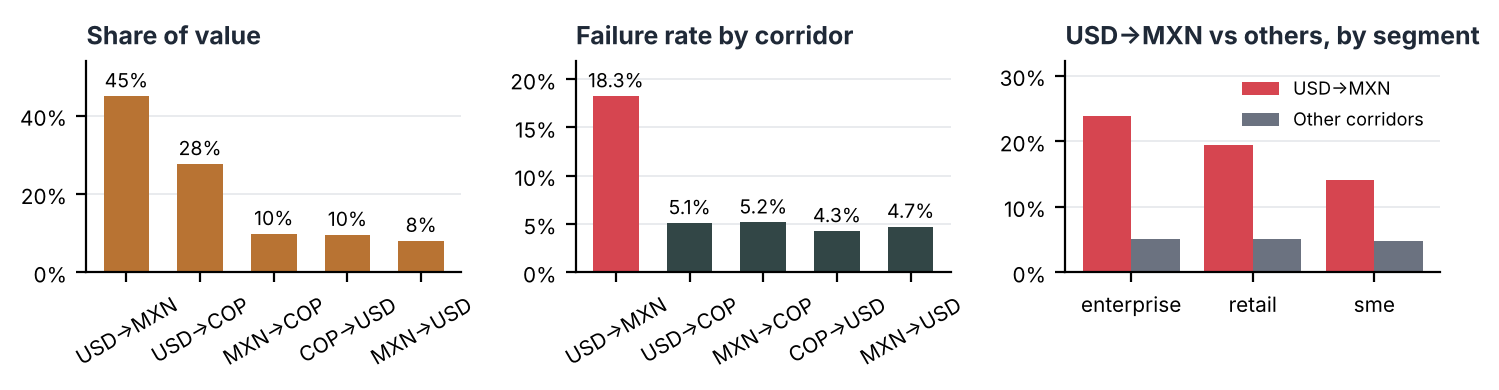

In [18]:
display(Markdown("\n".join(f"{i}. {t}" for i, t in enumerate(A.executive_summary(R), 1))))
display(Image(charts["summary"]))

### Use of AI

In [19]:
for note in A.AI_NOTES:
    display(Markdown("- " + note))

- Claude (Anthropic) was used to refactor the initial scripts into a modular package with a single metrics function (summarize) instead of five duplicated groupby blocks, to suggest the root-cause cuts and the chi² test to rule out the day-of-week effect, and to draft the write-up and memo.

- Own validation: the patterns stated in the brief were checked against the data. Two do not hold: Friday failures (18%) match every other day, and the segment with the highest failure rate is enterprise, not retail (retail does drive more failures by volume). A US$10K threshold test within SME was added to separate the amount effect from the segment effect.

- Python is the single source of truth: every figure and text is generated by `python main.py`; the Excel workbook and this document only load and display those results.

## Regenerate every deliverable
```bash
cd python
python main.py            # result tables (Part1/2/3 workbooks) + findings_report.md
python build_excel.py     # Cobre_Dashboard.xlsx
python build_document.py  # Cobre_Assessment_Deliverable.docx / .pdf
```